# Treino × teste por configuração — gráficos no formato da aula

Este notebook gera, para cada uma das 8 áreas do notebook 09, um gráfico no formato do exemplo da aula (árvore de decisão no KNIME), adaptado ao agrupamento:

| No exemplo da aula | Aqui |
|---|---|
| Uma barra por experimento | Uma barra por configuração: cenário × % do treino, mais os testes de escalonador e algoritmo |
| Barras com VP, FP, VN e FN | Barras empilhadas com o tamanho de cada grupo |
| Linhas de cobertura e precisão | Linhas de silhueta e Davies–Bouldin (e ARI no treino) |
| Painel de treino e painel de teste | Igual |

Linhas e barras ficam em faixas separadas, em vez de dois eixos verticais no mesmo gráfico, porque as três medidas têm escalas diferentes.

**Configurações (eixo horizontal):** C1 a C7 com 40%, 70% e 100% do treino, mais MinMax, Robust, K-medoids e Ward no C2 e no C5 (29 no total). Cada configuração usa o K escolhido no notebook 09 para o seu cenário. Quando esse K não cabe na amostra de 40% (menos de 10 cursos por grupo), a coluna aparece como "inviável".

**Origem dos dados:** as linhas são médias das 10 divisões do notebook 09. As barras refazem o ajuste da divisão 42 para obter o tamanho dos grupos no treino e no teste.

Os gráficos são salvos como `H_treino_teste_por_configuracao.png` na pasta de cada área, em `resultados_notebook_09/`, e registrados no MLflow, na pasta `graficos` da área.

In [1]:
# Célula 1 — Importações, parâmetros e resultados do notebook 09

import os
import warnings
from pathlib import Path

os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
os.environ["GIT_PYTHON_REFRESH"] = "quiet"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

# Mesmos parâmetros do notebook 09
AREAS = {
    5710: "Engenharia Civil", 6208: "Engenharia de Produção", 21: "Arquitetura e Urbanismo",
    5902: "Engenharia Mecânica", 5806: "Engenharia Elétrica", 6307: "Engenharia Ambiental",
    6008: "Engenharia Química", 5814: "Engenharia de Controle e Automação"
}
CENARIOS = ["C1_CPC", "C2_8IND", "C3_4DIM", "C4_PCA", "C5_SEM_REGIME", "C6_INSUMOS", "C7_SEM_REDUNDANCIA"]
CENARIOS_SENSIBILIDADE = ["C2_8IND", "C5_SEM_REGIME"]
PROPORCOES = [0.4, 0.7, 1.0]
SEMENTE = 42
TEST_SIZE = 0.20
MIN_POR_GRUPO = 10
N_INIT = 10

INDICADORES = [
    "Enade_2023", "IDD_2023", "Mestres_2023", "Doutores_2023",
    "Regime_Trabalho_2023", "Organizacao_Didatica_2023",
    "Infraestrutura_2023", "Oportunidades_2023"
]
INDICADORES_SEM_REGIME = [c for c in INDICADORES if c != "Regime_Trabalho_2023"]
INDICADORES_INSUMOS = ["Mestres_2023", "Doutores_2023", "Regime_Trabalho_2023",
                       "Organizacao_Didatica_2023", "Infraestrutura_2023", "Oportunidades_2023"]
INDICADORES_SEM_REDUNDANCIA = ["Enade_2023", "Mestres_2023", "Doutores_2023",
                               "Regime_Trabalho_2023", "Organizacao_Didatica_2023"]
EXPERIMENTO_MLFLOW = "CPC2023_agrupamento_por_area_C1_C7"

pasta09 = Path("resultados_notebook_09")
resumo = pd.read_csv(pasta09 / "resumo_por_configuracao.csv", sep=";", decimal=",")
escolhas = pd.read_csv(pasta09 / "k_escolhido_por_area.csv", sep=";", decimal=",")
log = pd.read_csv(pasta09 / "log_execucoes.csv", sep=";", decimal=",")

base = pd.read_csv("dados/processados/base_analitica_1907_cursos.csv", encoding="utf-8-sig")
base.columns = base.columns.str.replace("﻿", "", regex=False).str.strip()

print("Configurações lidas do notebook 09:", len(resumo))

Configurações lidas do notebook 09: 1434


In [2]:
# Célula 2 — Funções de preparação e ajuste (iguais às do notebook 09)

ESCALAS = {"Standard": StandardScaler, "MinMax": MinMaxScaler, "Robust": RobustScaler}


def criar_dimensoes_cpc(dados):
    return pd.DataFrame({
        "ENADE": dados["Enade_2023"],
        "IDD": dados["IDD_2023"],
        "Condicoes_Formacao": (7.5 * dados["Organizacao_Didatica_2023"]
                               + 5.0 * dados["Infraestrutura_2023"]
                               + 2.5 * dados["Oportunidades_2023"]) / 15.0,
        "Corpo_Docente": (7.5 * dados["Mestres_2023"]
                          + 15.0 * dados["Doutores_2023"]
                          + 7.5 * dados["Regime_Trabalho_2023"]) / 30.0
    }, index=dados.index)


def representar(dados, cenario):
    if cenario == "C1_CPC":
        return dados[["CPC_2023"]]
    if cenario == "C3_4DIM":
        return criar_dimensoes_cpc(dados)
    if cenario == "C5_SEM_REGIME":
        return dados[INDICADORES_SEM_REGIME]
    if cenario == "C6_INSUMOS":
        return dados[INDICADORES_INSUMOS]
    if cenario == "C7_SEM_REDUNDANCIA":
        return dados[INDICADORES_SEM_REDUNDANCIA]
    return dados[INDICADORES]


def preparar(cenario, treino, teste, escala):
    esc = ESCALAS[escala]().fit(representar(treino, cenario))
    X_treino = esc.transform(representar(treino, cenario))
    X_teste = esc.transform(representar(teste, cenario))
    if cenario == "C4_PCA":
        pca = PCA(n_components=2).fit(X_treino)
        X_treino, X_teste = pca.transform(X_treino), pca.transform(X_teste)
    return X_treino, X_teste


def k_medoides(D, k, semente, n_init=5, max_iter=50):
    gerador = np.random.default_rng(semente)
    melhor = (np.inf, None, None)
    n = len(D)
    for _ in range(n_init):
        medoides = [gerador.integers(n)]
        while len(medoides) < k:
            d_min = D[:, medoides].min(axis=1) ** 2
            medoides.append(gerador.choice(n, p=d_min / d_min.sum()))
        medoides = np.array(medoides)
        for _ in range(max_iter):
            rotulos = D[:, medoides].argmin(axis=1)
            novos = np.array([np.flatnonzero(rotulos == g)[
                D[np.ix_(rotulos == g, rotulos == g)].sum(axis=1).argmin()] for g in range(k)])
            if np.array_equal(np.sort(novos), np.sort(medoides)):
                break
            medoides = novos
        custo = D[np.arange(n), medoides[rotulos]].sum()
        if custo < melhor[0]:
            melhor = (custo, rotulos, medoides)
    return melhor[1], melhor[2]


def ajustar(algoritmo, X, k, semente):
    if algoritmo == "K-means":
        modelo = KMeans(n_clusters=k, random_state=semente, n_init=N_INIT).fit(X)
        return modelo.labels_, modelo.cluster_centers_
    if algoritmo == "Ward":
        rotulos = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
        return rotulos, np.array([X[rotulos == g].mean(axis=0) for g in range(k)])
    rotulos, medoides = k_medoides(pairwise_distances(X), k, semente)
    return rotulos, X[medoides]

In [3]:
# Célula 3 — Tabela por configuração: métricas médias (10 divisões) e tamanhos dos grupos (divisão 42)

CONFIGURACOES = []
for cen in CENARIOS:
    for p in PROPORCOES:
        CONFIGURACOES.append((f"{cen.split('_')[0]} {int(p * 100)}%", cen, "Standard", "K-means", p))
for cen in CENARIOS_SENSIBILIDADE:
    for rotulo, esc, alg in [("MinMax", "MinMax", "K-means"), ("Robust", "Robust", "K-means"),
                             ("K-medoids", "Standard", "K-medoids"), ("Ward", "Standard", "Ward")]:
        CONFIGURACOES.append((f"{cen.split('_')[0]} {rotulo}", cen, esc, alg, 1.0))


def tabela_area(codigo):
    dados = base[base["Area_2023"].eq(codigo)].reset_index(drop=True)
    k_cen = escolhas[escolhas["Area"] == codigo].set_index("Cenario")["K_escolhido"].to_dict()
    idx_treino, idx_teste = train_test_split(np.arange(len(dados)), test_size=TEST_SIZE, random_state=SEMENTE)
    ordem = np.random.default_rng(SEMENTE).permutation(idx_treino)
    linhas = []

    for rotulo, cen, esc, alg, p in CONFIGURACOES:
        k = int(k_cen[cen])
        linha = {"Area": codigo, "Configuracao": rotulo, "Cenario": cen, "Escalonador": esc,
                 "Algoritmo": alg, "Proporcao": p, "K": k}
        sub = ordem[:int(round(p * len(ordem)))]
        filtro = ((resumo["Area"] == codigo) & (resumo["Cenario"] == cen) & (resumo["Escalonador"] == esc)
                  & (resumo["Algoritmo"] == alg) & (resumo["Proporcao"] == p) & (resumo["K"] == k))
        if len(sub) // k < MIN_POR_GRUPO or not filtro.any():
            linhas.append(linha)        # configuração inviável: fica como lacuna no gráfico
            continue

        r = resumo[filtro].iloc[0]
        f_log = ((log["Area"] == codigo) & (log["Cenario"] == cen) & (log["Escalonador"] == esc)
                 & (log["Algoritmo"] == alg) & (log["Proporcao"] == p) & (log["K"] == k))
        linha.update(Silhueta_treino=r["Silhueta_treino"], Silhueta_teste=r["Silhueta_teste"],
                     DB_treino=log.loc[f_log, "DB_treino"].mean(), DB_teste=r["DB_teste"],
                     ARI=r["ARI_medio"])

        X_sub, X_teste = preparar(cen, dados.iloc[sub], dados.iloc[idx_teste], esc)
        rot_treino, centros = ajustar(alg, X_sub, k, SEMENTE)
        rot_teste = pairwise_distances(X_teste, centros).argmin(axis=1)
        ordem_g = np.argsort(-np.bincount(rot_treino, minlength=k))
        linha["Tamanhos_treino"] = np.bincount(rot_treino, minlength=k)[ordem_g].tolist()
        linha["Tamanhos_teste"] = np.bincount(rot_teste, minlength=k)[ordem_g].tolist()
        linhas.append(linha)

    return pd.DataFrame(linhas)


tabelas = {codigo: tabela_area(codigo) for codigo in AREAS}
treino_teste = pd.concat(tabelas.values(), ignore_index=True)

print("Engenharia Civil:")
display(tabelas[5710].drop(columns=["Area", "Cenario", "Escalonador", "Algoritmo", "Proporcao"]).round(3))

Engenharia Civil:


,Configuracao,K,Silhueta_treino,Silhueta_teste,DB_treino,DB_teste,ARI,Tamanhos_treino,Tamanhos_teste
0,C1 40%,2,0.603,0.586,0.538,0.550,0.928,"[90, 54]","[61, 30]"
1,C1 70%,2,0.601,0.591,0.542,0.547,0.973,"[162, 90]","[61, 30]"
2,C1 100%,2,0.600,0.591,0.546,0.546,0.986,"[227, 133]","[61, 30]"
3,C2 40%,4,0.276,0.249,1.239,1.255,0.760,"[50, 44, 29, 21]","[25, 27, 17, 22]"
4,C2 70%,4,0.275,0.256,1.274,1.249,0.896,"[83, 80, 50, 39]","[27, 25, 18, 21]"
5,C2 100%,4,0.272,0.258,1.287,1.236,0.948,"[112, 108, 76, 64]","[27, 25, 17, 22]"
6,C3 40%,4,0.307,0.283,1.082,1.112,0.774,"[46, 41, 29, 28]","[29, 21, 24, 17]"
7,C3 70%,4,0.308,0.289,1.093,1.108,0.861,"[83, 74, 50, 45]","[27, 23, 19, 22]"
8,C3 100%,4,0.306,0.292,1.094,1.099,0.930,"[108, 107, 77, 68]","[28, 22, 19, 22]"
9,C4 40%,3,0.410,0.403,0.829,0.822,0.863,"[59, 51, 34]","[36, 39, 16]"


## Como ler

- **Treino e teste próximos** nas linhas indicam que os grupos generalizam para cursos que o modelo não viu.
- **ARI subindo de 40% para 100%** indica que mais cursos de treino deixam os grupos mais estáveis.
- **Barras parecidas no treino e no teste** indicam que a proporção dos grupos se mantém.
- **C1 e C4** têm silhueta alta e Davies–Bouldin baixo, mas o notebook 09 mostrou que isso vem de usar poucas dimensões, não de grupos reais.

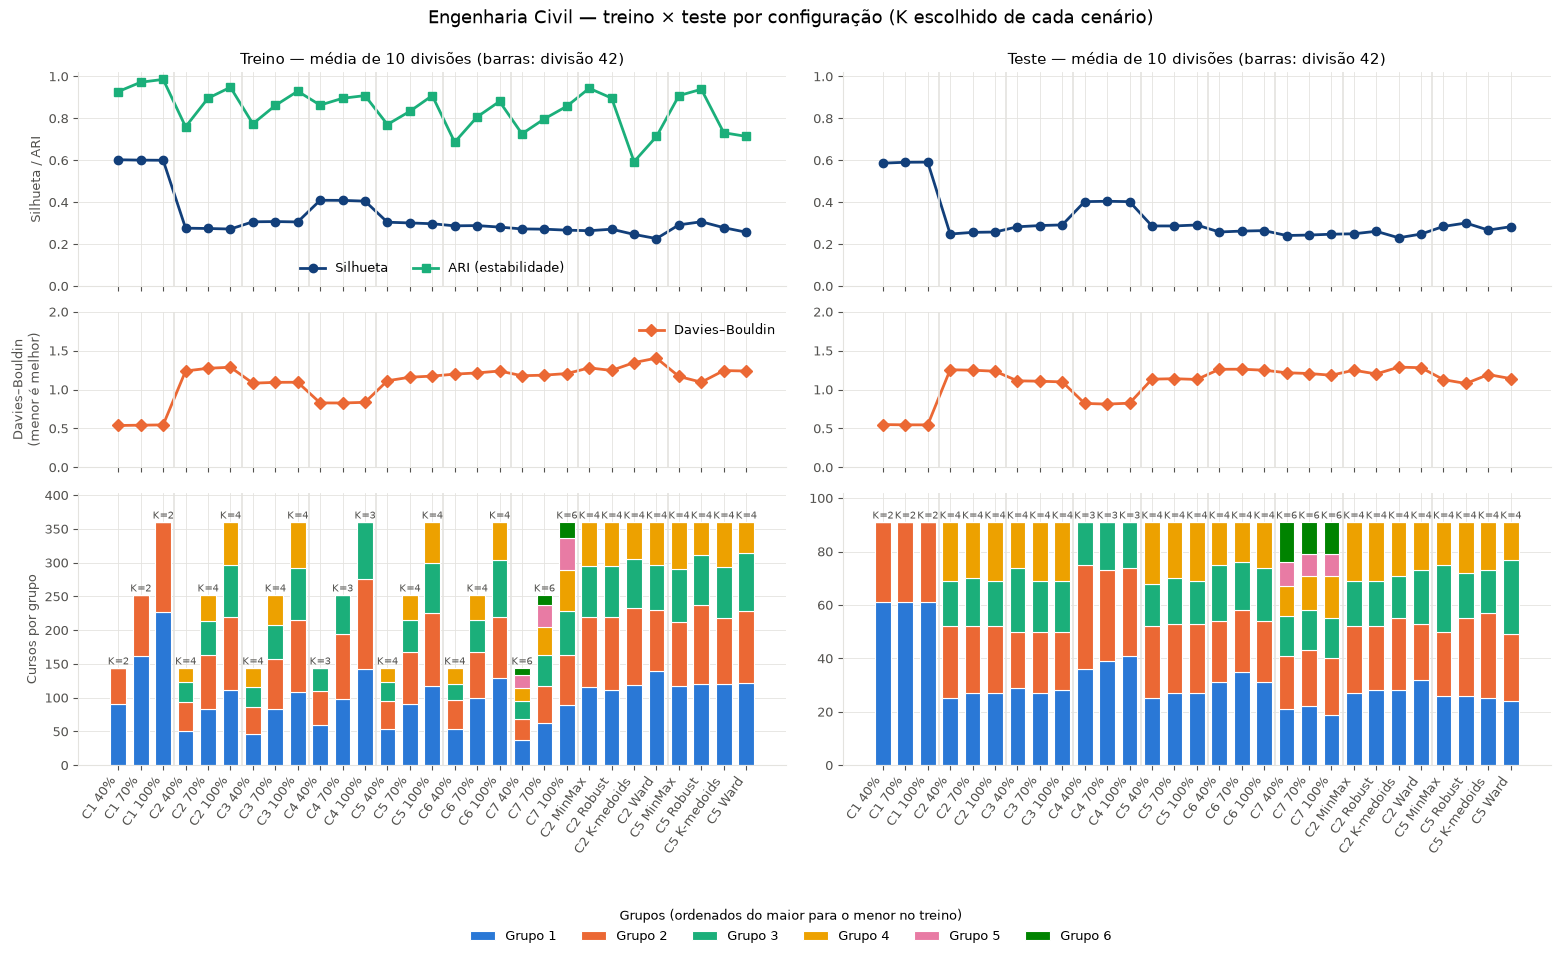

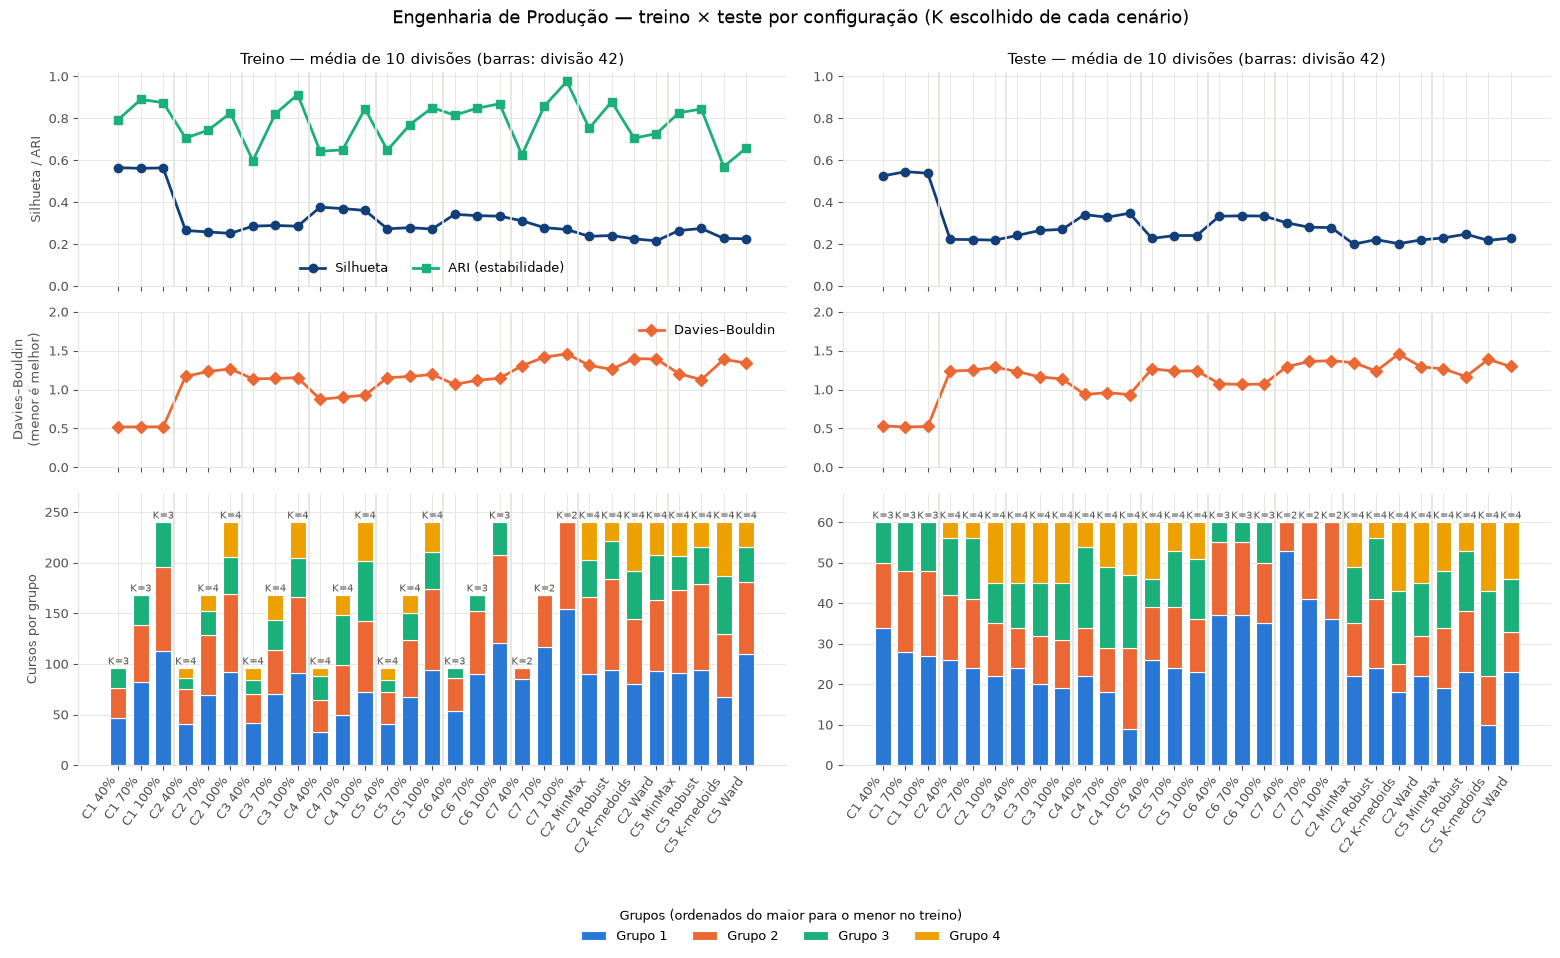

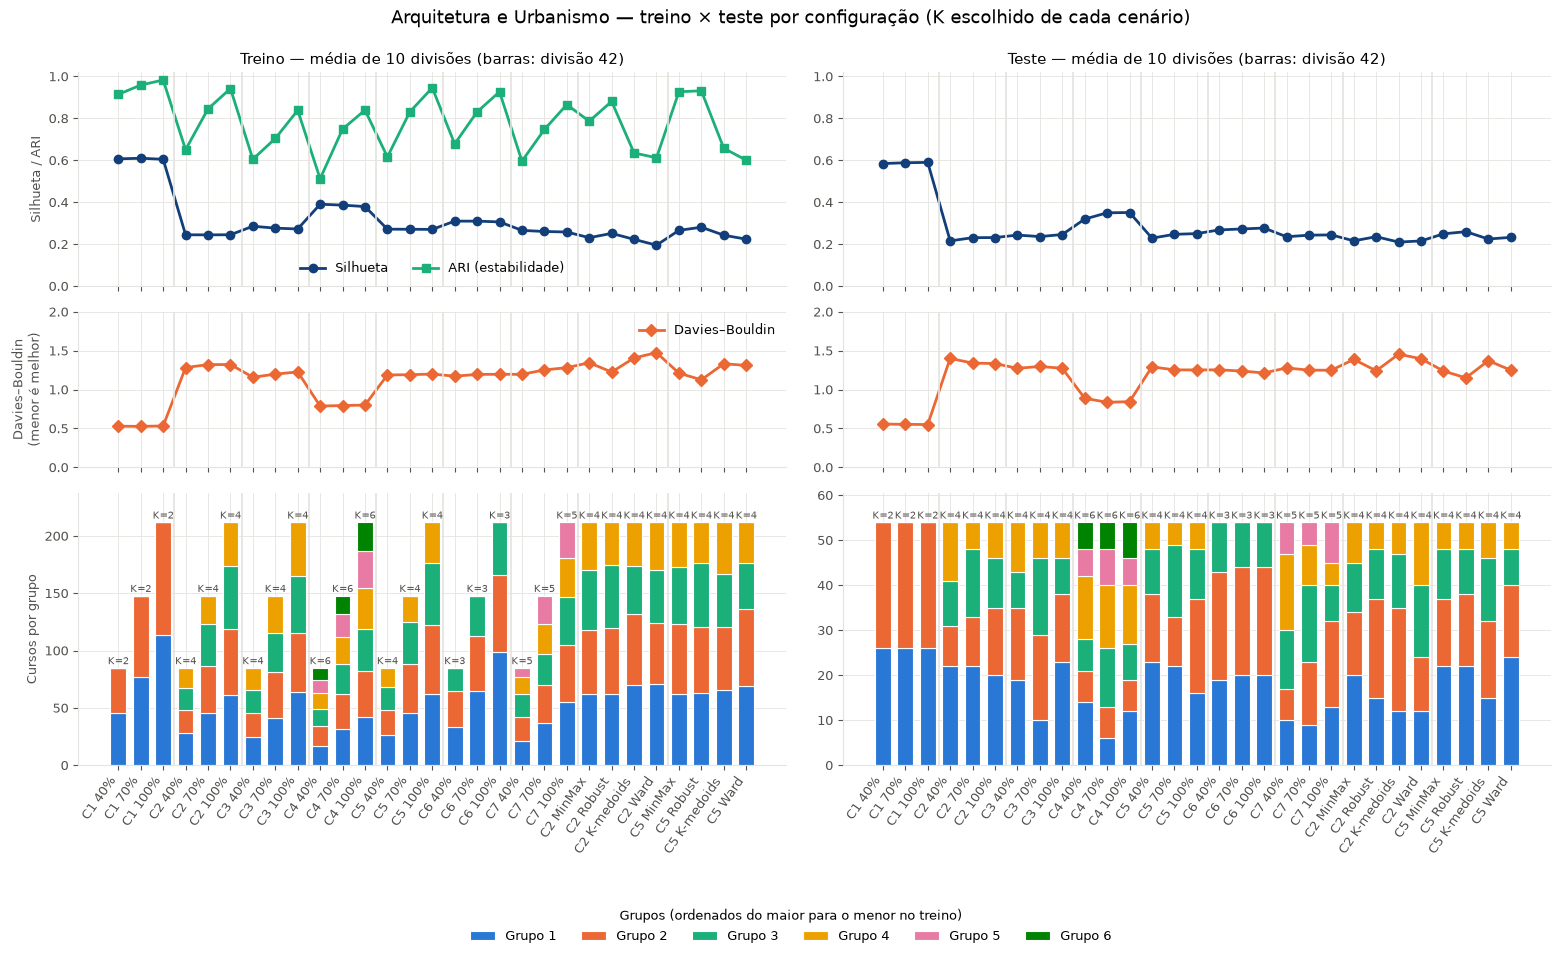

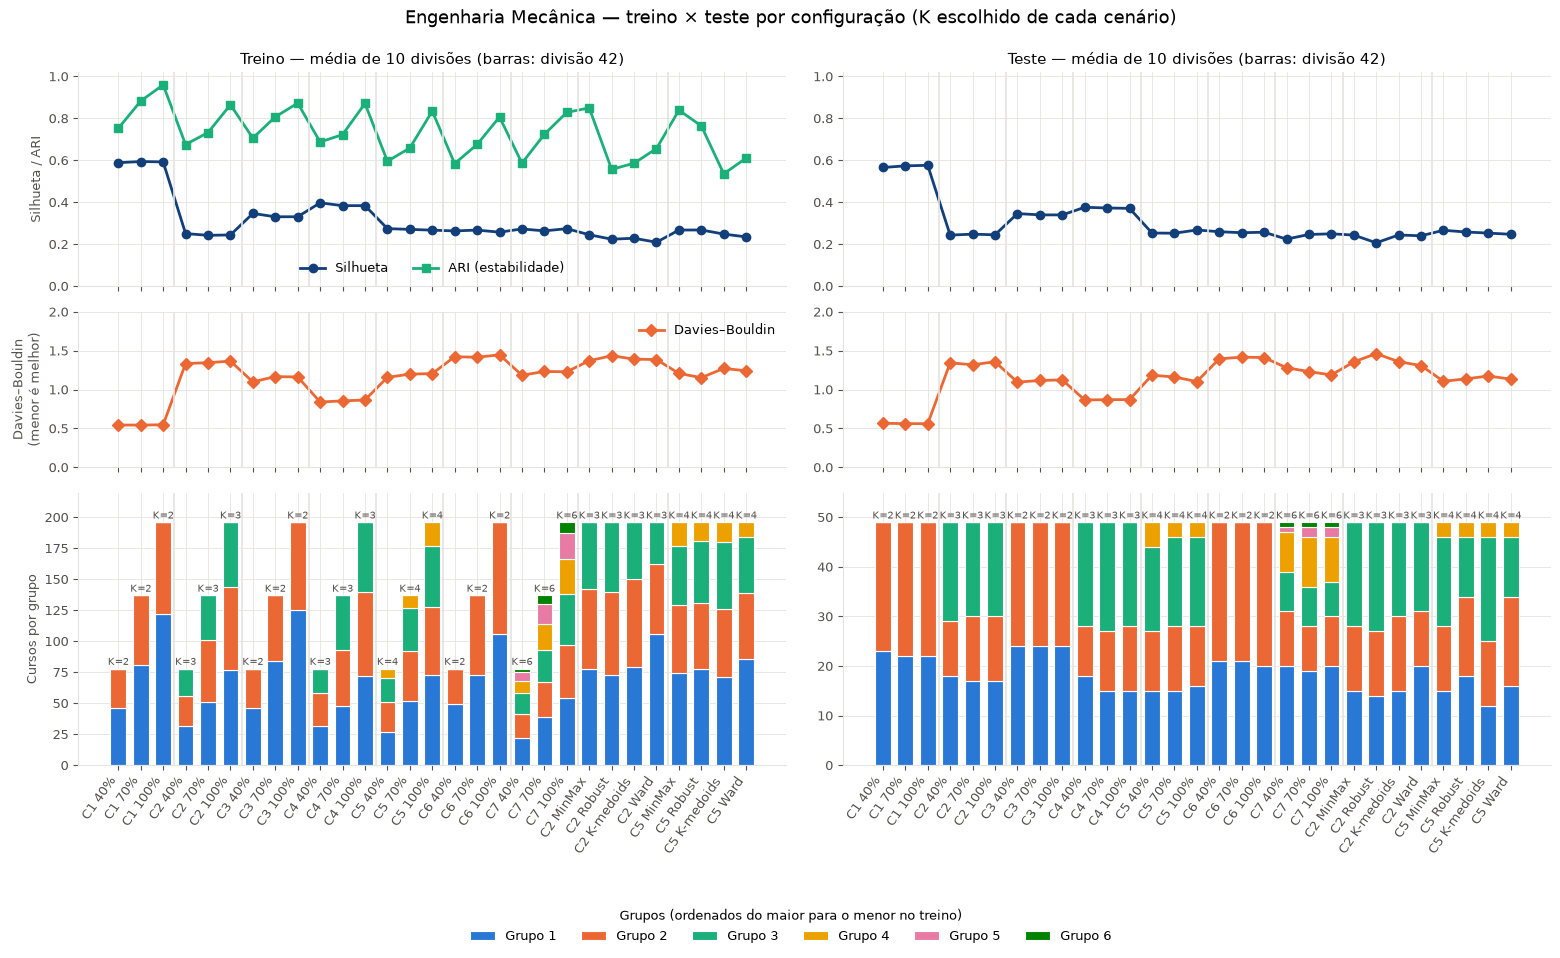

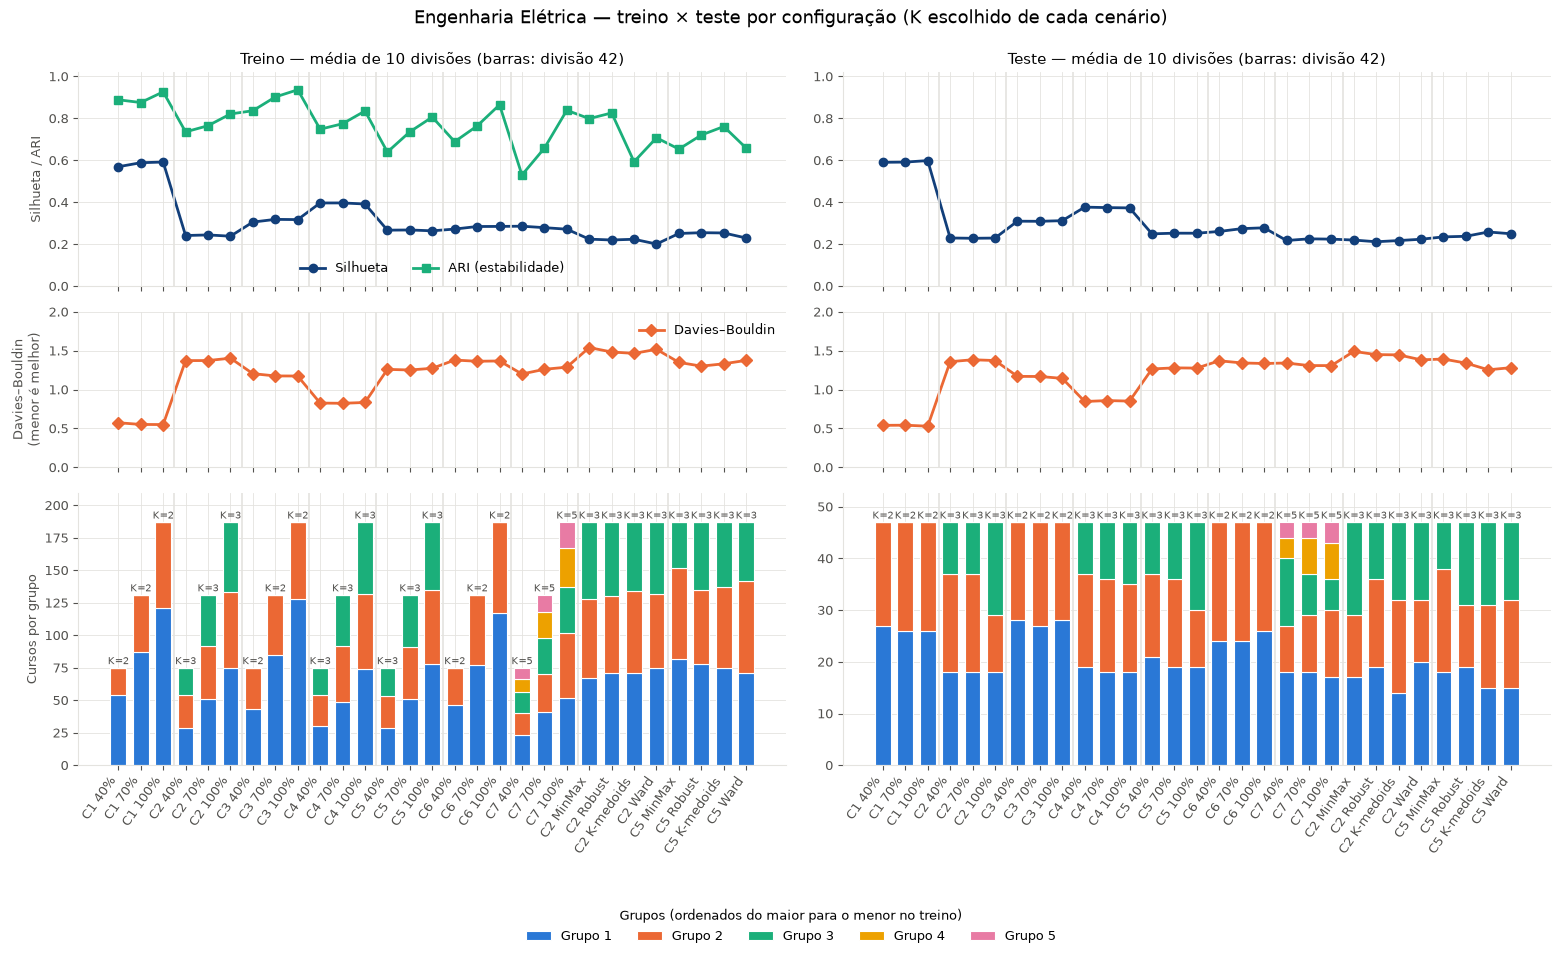

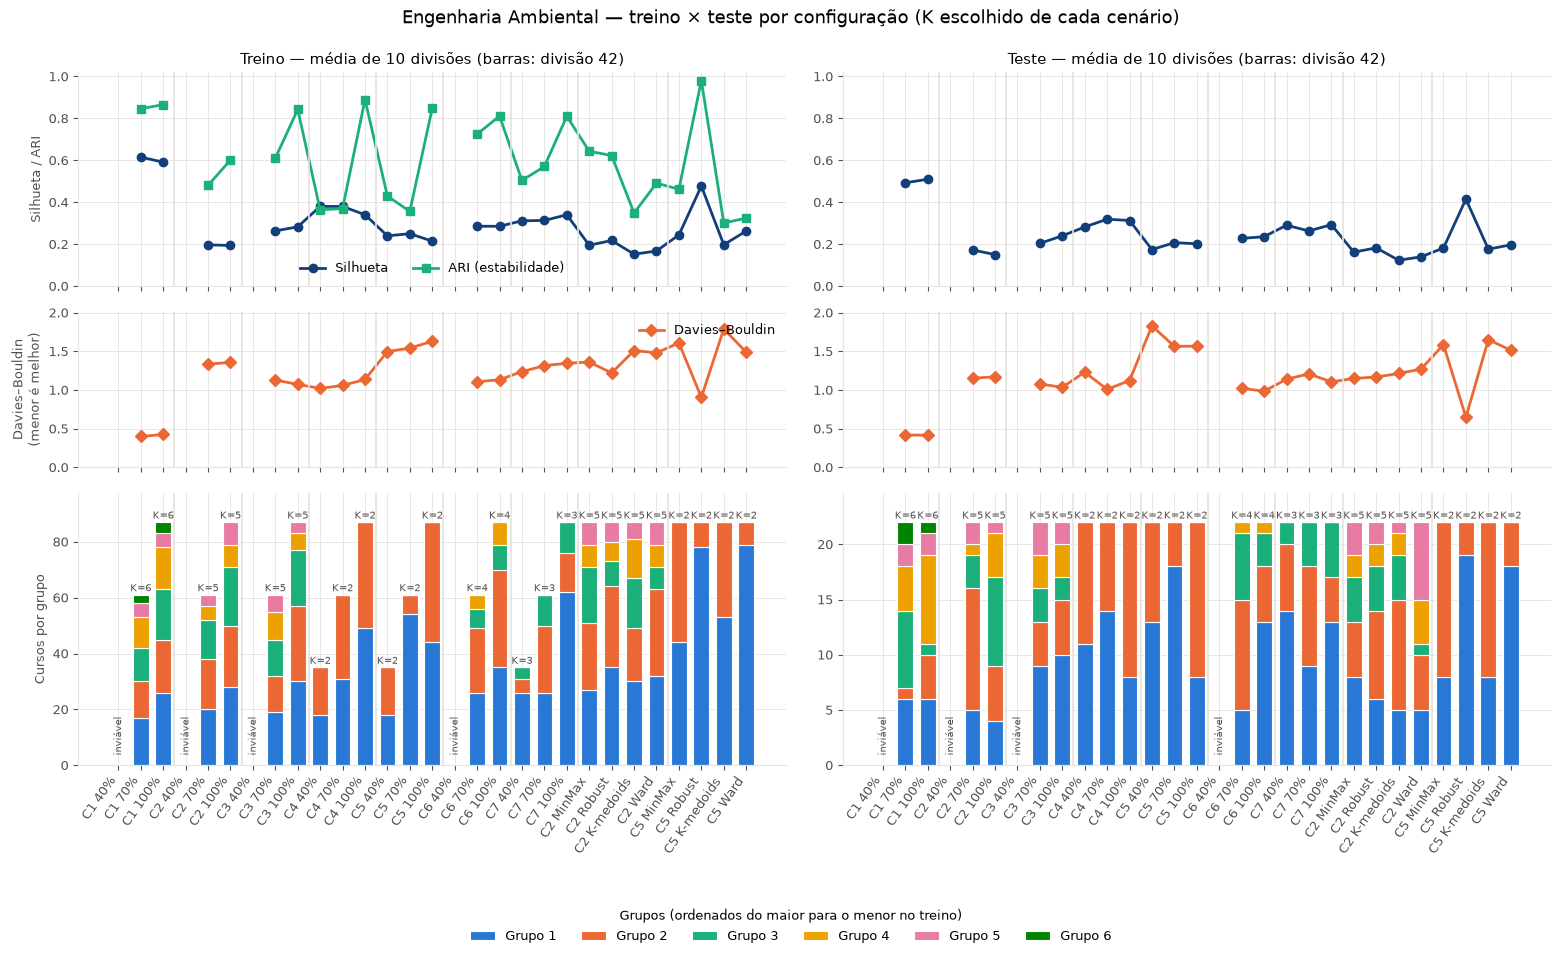

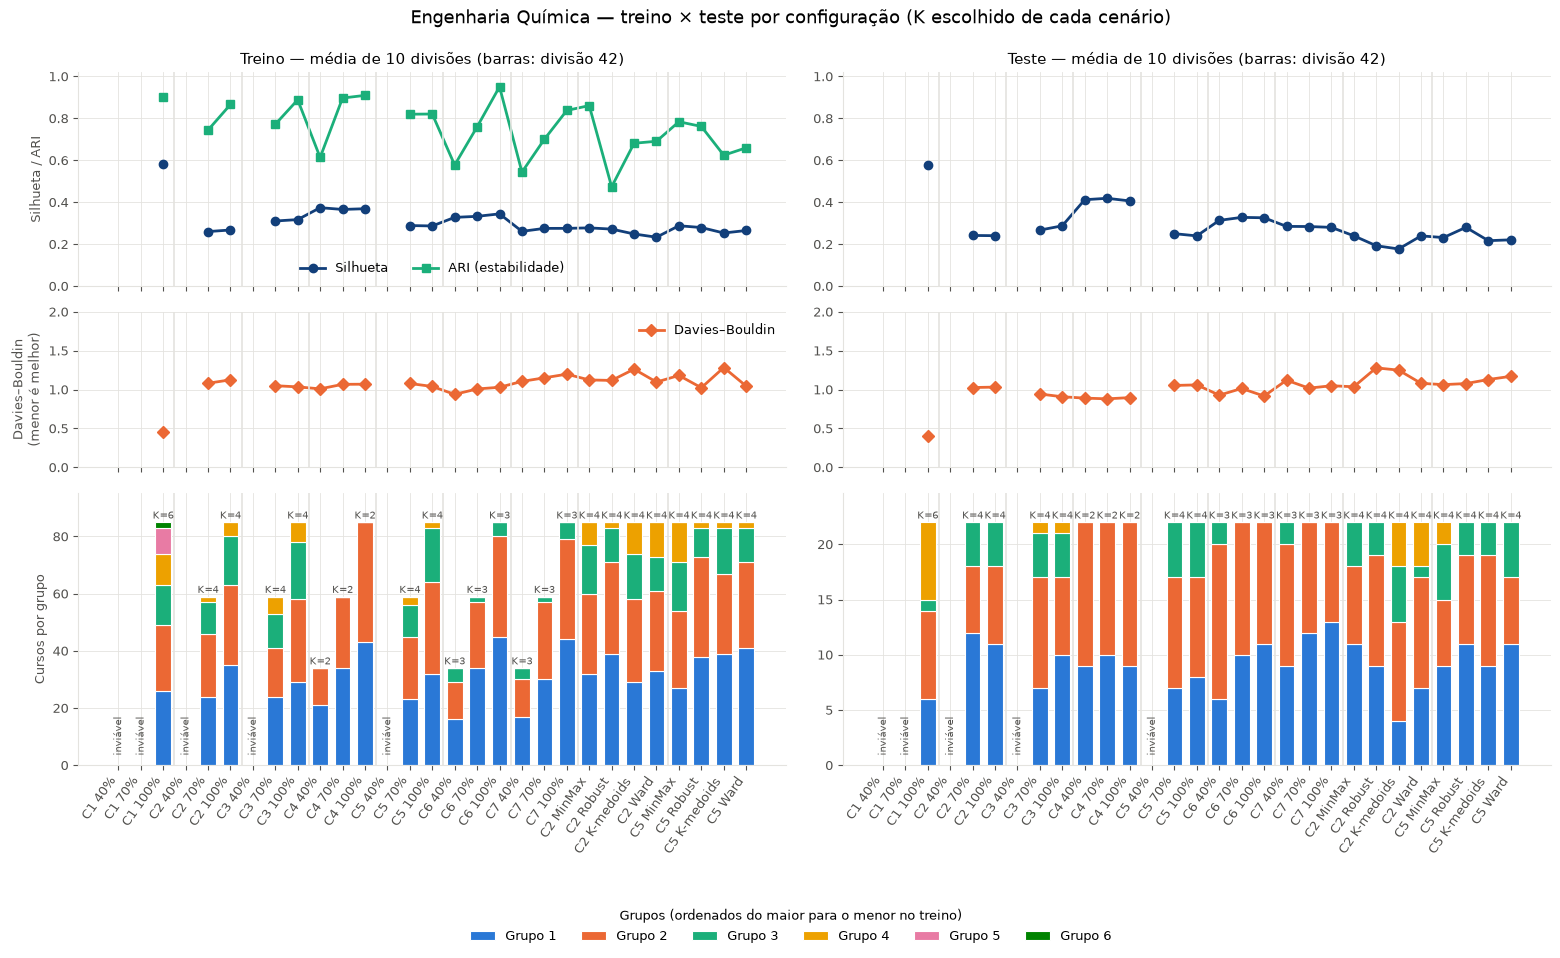

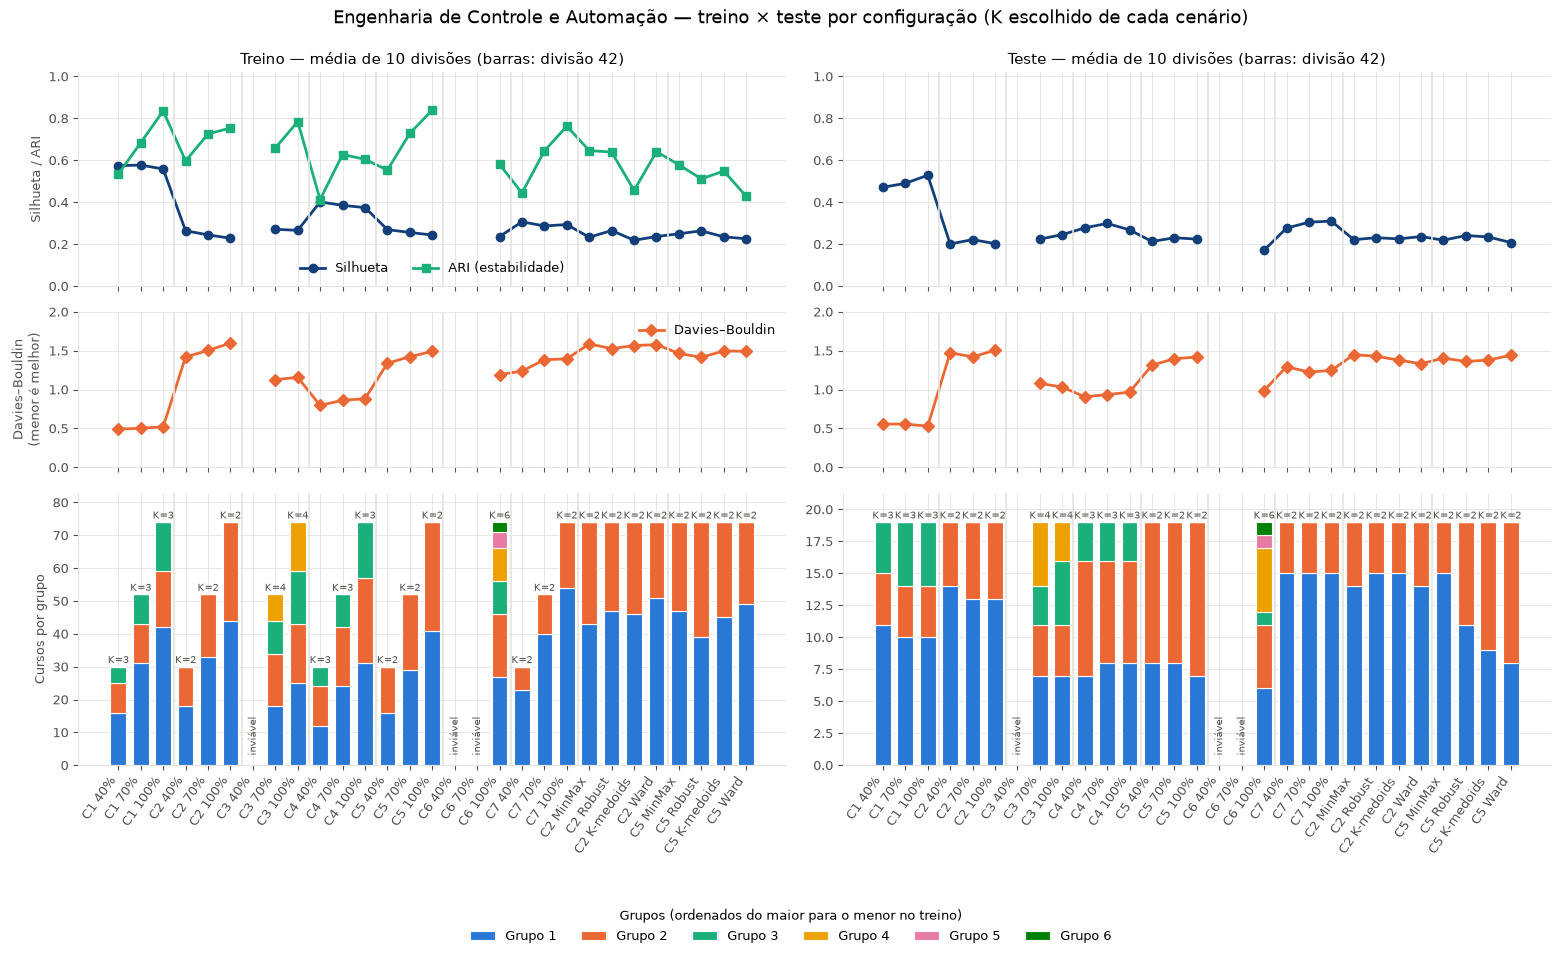

In [4]:
# Célula 4 — Gráfico treino × teste por configuração (formato do exemplo da aula)

CORES_G = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
COR_TXT, COR_GRADE = "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": COR_GRADE, "axes.grid": True, "axes.axisbelow": True,
                     "grid.color": COR_GRADE, "grid.linewidth": 0.6, "xtick.color": COR_TXT,
                     "ytick.color": COR_TXT, "axes.labelcolor": COR_TXT, "legend.frameon": False})

SEPARADORES = [2.5, 5.5, 8.5, 11.5, 14.5, 17.5, 20.5, 24.5]   # limites entre blocos de cenários


def grafico_treino_teste(codigo):
    t = tabelas[codigo]
    x = np.arange(len(t))
    fig, eixos = plt.subplots(3, 2, figsize=(19, 9), sharex=True,
                              gridspec_kw={"height_ratios": [1.1, 0.8, 1.4], "hspace": 0.12, "wspace": 0.08})
    db_max = np.nanmax(t[["DB_treino", "DB_teste"]].to_numpy(dtype=float))

    for col, (fase, sil, db, tam) in enumerate([("Treino", "Silhueta_treino", "DB_treino", "Tamanhos_treino"),
                                                 ("Teste", "Silhueta_teste", "DB_teste", "Tamanhos_teste")]):
        ax_s, ax_d, ax_b = eixos[:, col]
        ax_s.plot(x, t[sil], marker="o", color="#123f7a", linewidth=2, label="Silhueta")
        if fase == "Treino":
            ax_s.plot(x, t["ARI"], marker="s", color="#1baf7a", linewidth=2, label="ARI (estabilidade)")
        ax_s.set_ylim(0, 1.02)
        ax_s.set_title(f"{fase} — média de 10 divisões (barras: divisão 42)", fontsize=11)
        ax_d.plot(x, t[db], marker="D", color="#eb6834", linewidth=2, label="Davies–Bouldin")
        ax_d.set_ylim(0, max(2.0, db_max * 1.1))

        topo = np.zeros(len(t))
        for g in range(8):
            alturas = np.array([v[g] if isinstance(v, list) and g < len(v) else 0 for v in t[tam]])
            if alturas.sum() == 0:
                continue
            ax_b.bar(x, alturas, bottom=topo, color=CORES_G[g], width=0.7, edgecolor="white",
                     linewidth=0.8, label=f"Grupo {g + 1}")
            topo += alturas
        ax_b.set_ylim(0, topo.max() * 1.12)
        for xi, kk, total in zip(x, t["K"], topo):
            if total > 0:
                ax_b.text(xi, total + topo.max() * 0.015, f"K={kk}", ha="center", fontsize=7, color=COR_TXT)
            else:
                ax_b.text(xi, topo.max() * 0.05, "inviável", ha="center", rotation=90, fontsize=7, color=COR_TXT)

        if col == 0:
            ax_s.set_ylabel("Silhueta / ARI")
            ax_d.set_ylabel("Davies–Bouldin\n(menor é melhor)")
            ax_b.set_ylabel("Cursos por grupo")
        ax_b.set_xticks(x, t["Configuracao"], rotation=55, ha="right")
        for sep in SEPARADORES:
            for ax in (ax_s, ax_d, ax_b):
                ax.axvline(sep, color=COR_GRADE, linewidth=1.2)

    eixos[0, 0].legend(loc="lower center", ncols=2)
    eixos[1, 0].legend(loc="upper right")
    identificadores, nomes = eixos[2, 0].get_legend_handles_labels()
    fig.legend(identificadores, nomes, loc="lower center", ncols=8, bbox_to_anchor=(0.5, -0.1),
               title="Grupos (ordenados do maior para o menor no treino)")
    fig.suptitle(f"{AREAS[codigo]} — treino × teste por configuração (K escolhido de cada cenário)",
                 fontsize=13, y=0.95)

    pasta = pasta09 / (f"{codigo}_" + AREAS[codigo].replace(" ", "_").replace("ç", "c")
                       .replace("ã", "a").replace("é", "e"))
    pasta.mkdir(exist_ok=True)
    caminho = pasta / "H_treino_teste_por_configuracao.png"
    fig.savefig(caminho, dpi=160, bbox_inches="tight")
    plt.show()
    return caminho


arquivos_h = {codigo: grafico_treino_teste(codigo) for codigo in AREAS}

In [5]:
# Célula 5 — Exportar a tabela e registrar os gráficos no MLflow (dentro de cada área)

saida = treino_teste.copy()
for col in ["Tamanhos_treino", "Tamanhos_teste"]:
    saida[col] = saida[col].apply(lambda v: " | ".join(map(str, v)) if isinstance(v, list) else "")
saida.to_csv(pasta09 / "treino_teste_por_configuracao.csv", index=False, sep=";", decimal=",",
             encoding="utf-8-sig")

mlflow.set_tracking_uri("sqlite:///" + Path("mlflow_cpc.db").resolve().as_posix())
cliente = mlflow.MlflowClient()
runs_area = mlflow.search_runs(experiment_names=[EXPERIMENTO_MLFLOW],
                               filter_string="tags.nivel = 'area'", order_by=["start_time DESC"])

for codigo, caminho in arquivos_h.items():
    run = runs_area[runs_area["params.area_codigo"] == str(codigo)].iloc[0]   # execução mais recente da área
    cliente.log_artifact(run.run_id, str(caminho), artifact_path="graficos")
    print(f"{AREAS[codigo]}: gráfico H registrado no run {run.run_id[:8]}")

Engenharia Civil: gráfico H registrado no run fb6aa461
Engenharia de Produção: gráfico H registrado no run 624d7a03
Arquitetura e Urbanismo: gráfico H registrado no run 9d0a7fa1
Engenharia Mecânica: gráfico H registrado no run 7b533d2c
Engenharia Elétrica: gráfico H registrado no run 8aaa2524
Engenharia Ambiental: gráfico H registrado no run 1dac17d7
Engenharia Química: gráfico H registrado no run 727f5617
Engenharia de Controle e Automação: gráfico H registrado no run f03fb802
